<a href="https://colab.research.google.com/github/itsabhi-21/Prognos/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prognos: Remaining Useful Life Prediction for Turbofan Engines
## Notebook 2: Exploratory Data Analysis (EDA)

**Goal:** Understand how sensors behave as engines degrade, which sensors are informative, and how the operating conditions affect the data. The findings drive the preprocessing choices in the next notebook.

**Input:** processed files from Notebook 1 (train/test with RUL labels).

## 1. Setup and loading processed data

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from google.colab import drive

drive.mount('/content/drive')
PROC_DIR = '/content/drive/MyDrive/Prognos/processed'

OP_COLS = [f'op{i}' for i in range(1, 4)]
SENSOR_COLS = [f's{i}' for i in range(1, 22)]
SUBSETS = ['FD001', 'FD002', 'FD003', 'FD004']

train = {fd: pd.read_csv(f'{PROC_DIR}/train_{fd}_clean.csv') for fd in SUBSETS}
test = {fd: pd.read_csv(f'{PROC_DIR}/test_{fd}_clean.csv') for fd in SUBSETS}
rul_true = {fd: pd.read_csv(f'{PROC_DIR}/rul_{fd}.csv') for fd in SUBSETS}

print({fd: train[fd].shape for fd in SUBSETS})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'FD001': (20631, 28), 'FD002': (53759, 28), 'FD003': (24720, 28), 'FD004': (61249, 28)}


## 2. Which sensors are informative?
Sensors with 5 or fewer unique values (constant or almost constant) were flagged in Notebook 1. Here the remaining "active" sensors of FD001 are selected for closer inspection.

In [12]:
def active_sensors(df):
    return [c for c in SENSOR_COLS if df[c].nunique() > 5]

df1 = train['FD001']
active_fd1 = active_sensors(df1)
print(len(active_fd1), active_fd1)

14 ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 3. How do sensors change as an engine approaches failure? (FD001)
Five randomly chosen engines are plotted for every active sensor. The x-axis is RUL (cycles left) and is reversed, so time flows from left (healthy) to right (failure).
A sensor that shows a consistent rise or fall towards failure is a useful signal; a sensor that only shows noise is not.

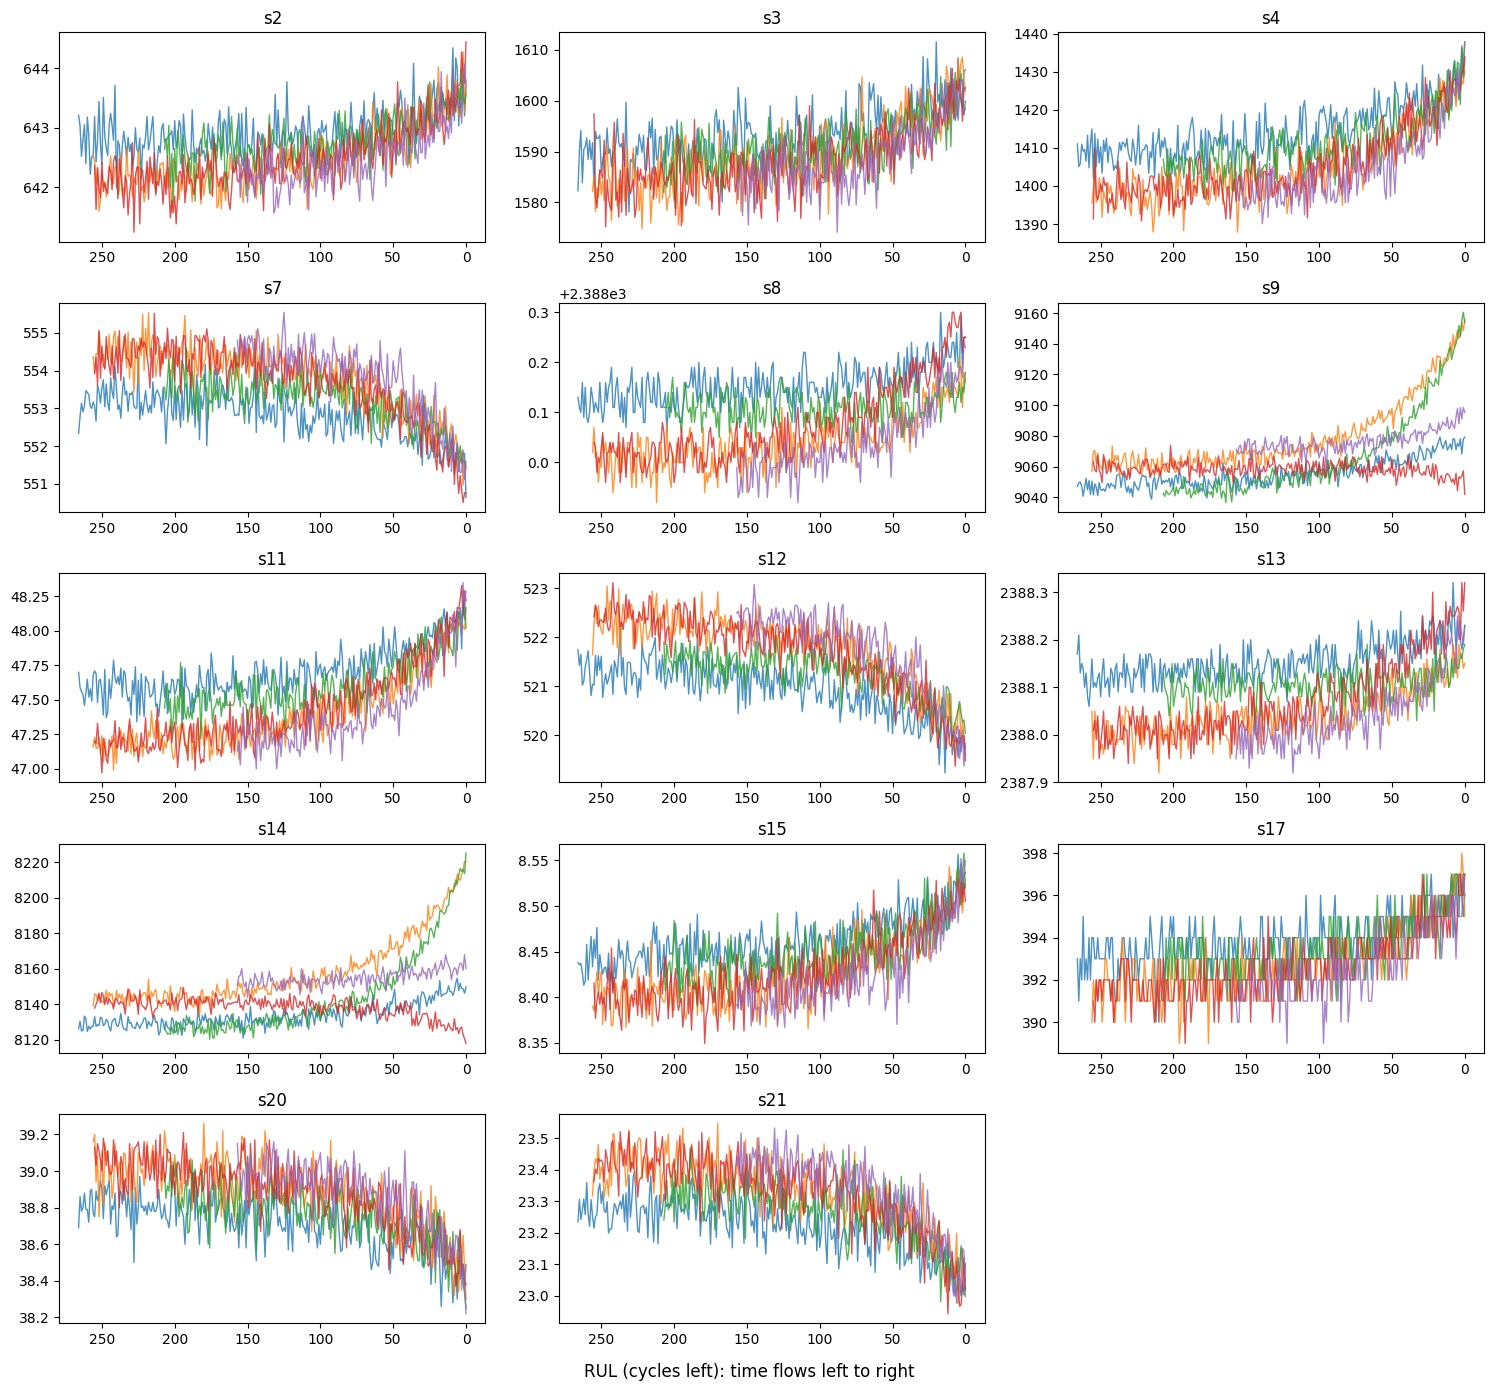

In [13]:
rng = np.random.RandomState(42)
sample_units = rng.choice(df1['unit'].unique(), 5, replace=False)

fig, axes = plt.subplots(5, 3, figsize=(15, 14))
axes = axes.ravel()
for ax, s in zip(axes, active_fd1):
    for u in sample_units:
        e = df1[df1['unit'] == u]
        ax.plot(e['RUL'], e[s], alpha=0.8, lw=1)
    ax.set_title(s)
    ax.invert_xaxis()
for ax in axes[len(active_fd1):]:
    ax.set_visible(False)
fig.supxlabel('RUL (cycles left): time flows left to right')
plt.tight_layout()
plt.show()

## 4. Correlation of each sensor with RUL (FD001)
Spearman correlation is used because degradation trends are monotonic but not always linear. Values close to +1 or -1 mean the sensor moves together with RUL; values near 0 mean little relation.

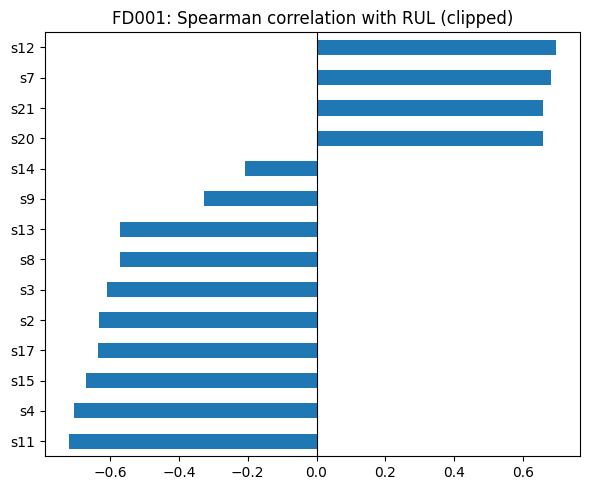

,RUL_clipped
s11,-0.72
s4,-0.70
s15,-0.67
s17,-0.64
s2,-0.63
s3,-0.61
s8,-0.57
s13,-0.57
s9,-0.33
s14,-0.21


In [14]:
corr_rul = (df1[active_fd1 + ['RUL_clipped']]
            .corr(method='spearman')['RUL_clipped']
            .drop('RUL_clipped')
            .sort_values())

plt.figure(figsize=(6, 5))
corr_rul.plot.barh()
plt.axvline(0, color='k', lw=0.8)
plt.title('FD001: Spearman correlation with RUL (clipped)')
plt.tight_layout()
plt.show()
corr_rul.round(2)

## 5. Sensor-to-sensor correlation (FD001)
Highly correlated sensors carry similar information (redundancy). This helps decide whether all sensors are needed for modelling.

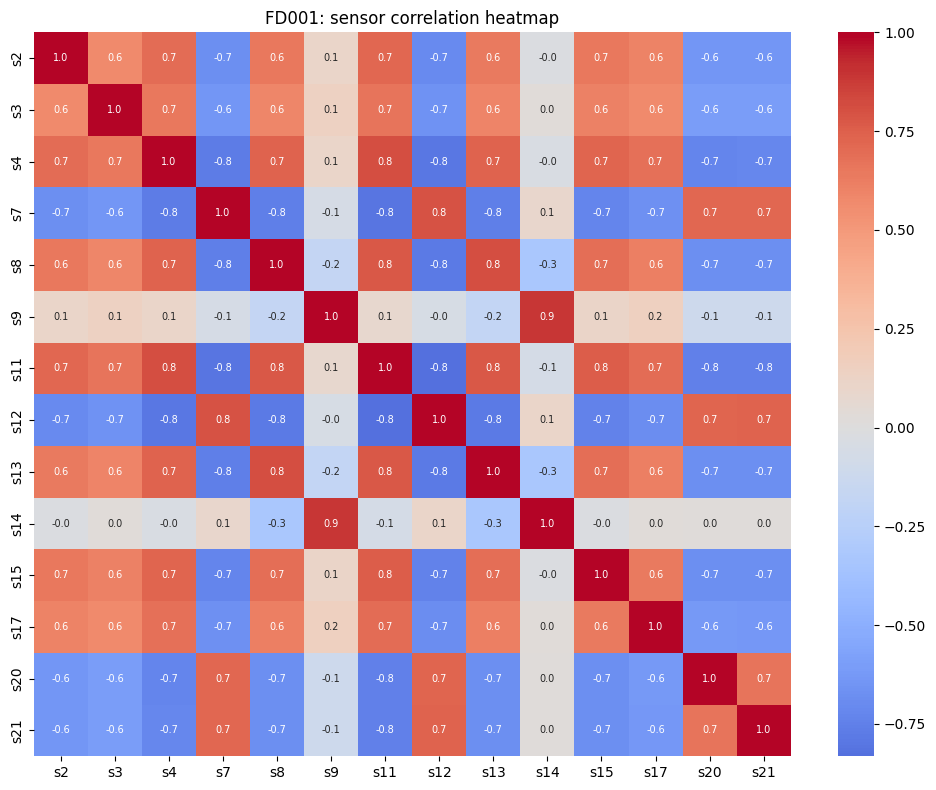

In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(df1[active_fd1].corr(method='spearman'),
            cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('FD001: sensor correlation heatmap')
plt.tight_layout()
plt.show()

## 6. Verifying the number of operating conditions (FD002 and FD004)
In Notebook 1 a rounding heuristic found 7 operating conditions where the documentation says 6.
Here K-Means clustering on the three operational settings is used instead. The elbow plot shows how the clustering error (inertia) falls as the number of clusters k increases; a sharp bend marks the natural number of groups.

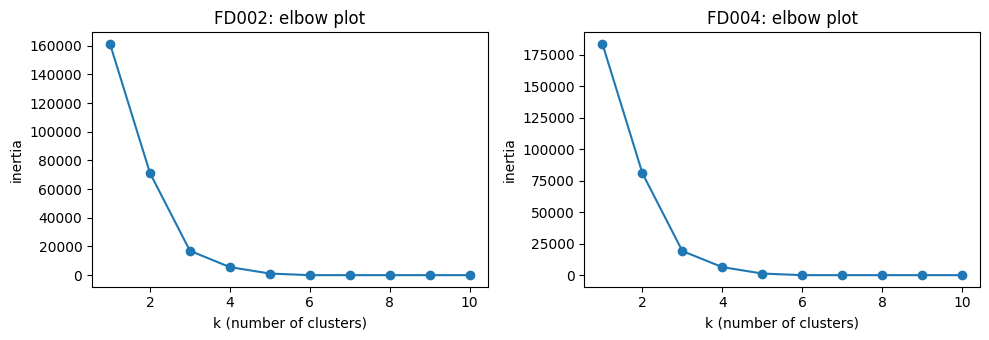

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, fd in zip(axes, ['FD002', 'FD004']):
    X = StandardScaler().fit_transform(train[fd][OP_COLS])
    inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_
                for k in range(1, 11)]
    ax.plot(range(1, 11), inertias, marker='o')
    ax.set_title(f'{fd}: elbow plot')
    ax.set_xlabel('k (number of clusters)')
    ax.set_ylabel('inertia')
plt.tight_layout()
plt.show()

## 7. Assigning an operating-condition label to every row
K-Means (k=6) is fitted on the training data of FD002 and FD004 and then applied to the test data. FD001 and FD003 have a single condition, so they get label 0.
The cluster sizes and the average settings of each cluster are printed as a sanity check.

In [17]:
def add_condition(fd, k=6):
    tr, te = train[fd], test[fd]
    if fd in ('FD002', 'FD004'):
        sc = StandardScaler().fit(tr[OP_COLS])
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(sc.transform(tr[OP_COLS]))
        tr['cond'] = km.labels_
        te['cond'] = km.predict(sc.transform(te[OP_COLS]))
    else:
        tr['cond'] = 0
        te['cond'] = 0

for fd in SUBSETS:
    add_condition(fd)

for fd in ['FD002', 'FD004']:
    print(fd, 'train cluster sizes:', train[fd]['cond'].value_counts().sort_index().to_dict())
    print(fd, 'test cluster sizes: ', test[fd]['cond'].value_counts().sort_index().to_dict())
    print(train[fd].groupby('cond')[OP_COLS].mean().round(3))
    print()

FD002 train cluster sizes: {0: 13458, 1: 8044, 2: 8122, 3: 8002, 4: 8096, 5: 8037}
FD002 test cluster sizes:  {0: 8483, 1: 5148, 2: 5063, 3: 5042, 4: 5107, 5: 5148}
         op1    op2    op3
cond                      
0     42.003  0.840  100.0
1      0.002  0.000  100.0
2     20.003  0.701  100.0
3     25.003  0.621   60.0
4     10.003  0.250  100.0
5     35.003  0.841  100.0

FD004 train cluster sizes: {0: 15395, 1: 9224, 2: 9139, 3: 9091, 4: 9238, 5: 9162}
FD004 test cluster sizes:  {0: 10382, 1: 6185, 2: 6107, 3: 6254, 4: 6054, 5: 6232}
         op1    op2    op3
cond                      
0     42.003  0.840  100.0
1     10.003  0.251  100.0
2     25.003  0.621   60.0
3     20.003  0.701  100.0
4      0.002  0.000  100.0
5     35.003  0.841  100.0



## 8. Why per-condition normalisation matters (FD002 example)
In multi-condition subsets, a sensor value depends on the operating condition as well as on engine health. Below, one FD002 engine is shown with a raw sensor and with the same sensor standardised within each condition (subtract the condition's mean, divide by its standard deviation).

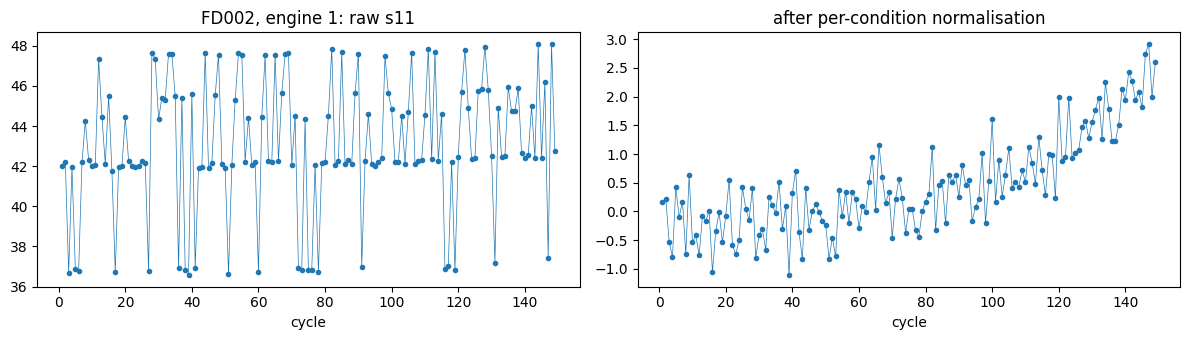

In [18]:
fd, s = 'FD002', 's11'
df = train[fd]
unit = df['unit'].iloc[0]
e = df[df['unit'] == unit].copy()

stats = df.groupby('cond')[s].agg(['mean', 'std'])
e[s + '_norm'] = (e[s] - e['cond'].map(stats['mean'])) / e['cond'].map(stats['std'])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
axes[0].plot(e['cycle'], e[s], marker='.', lw=0.5)
axes[0].set_title(f'{fd}, engine {unit}: raw {s}')
axes[1].plot(e['cycle'], e[s + '_norm'], marker='.', lw=0.5)
axes[1].set_title('after per-condition normalisation')
for ax in axes:
    ax.set_xlabel('cycle')
plt.tight_layout()
plt.show()

## 9. True RUL of the test engines
The RUL files give the true remaining life of each test engine at its last recorded cycle. Their distribution shows which RUL range the final evaluation will cover.

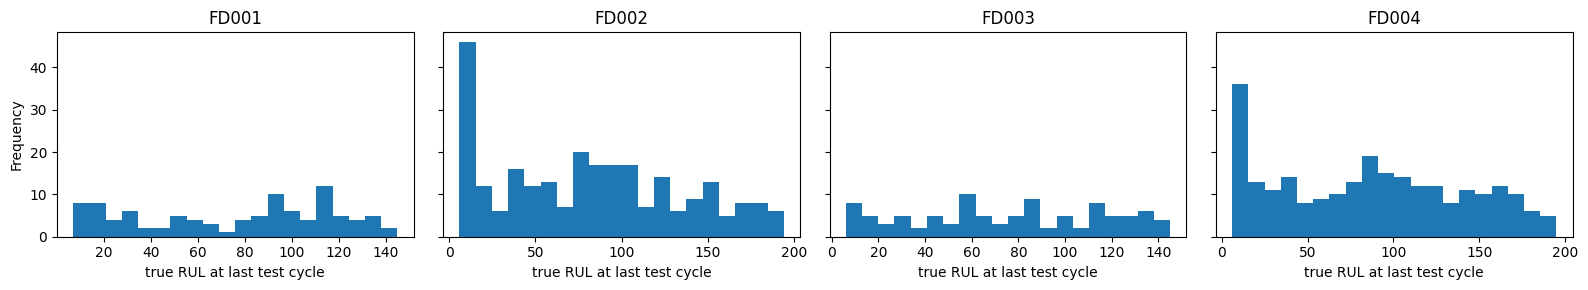

,FD001,FD002,FD003,FD004
count,100.0,259.0,100.0,248.0
mean,75.5,81.2,75.3,86.6
std,41.8,53.9,41.6,54.6
min,7.0,6.0,6.0,6.0
25%,32.8,35.0,43.2,36.0
50%,86.0,80.0,77.5,88.0
75%,112.2,121.0,115.0,126.8
max,145.0,194.0,145.0,195.0


In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, fd in zip(axes, SUBSETS):
    rul_true[fd]['RUL'].plot.hist(bins=20, ax=ax)
    ax.set_title(fd)
    ax.set_xlabel('true RUL at last test cycle')
plt.tight_layout()
plt.show()

pd.DataFrame({fd: rul_true[fd]['RUL'].describe() for fd in SUBSETS}).round(1)

## 10. Saving files with the condition label

In [20]:
for fd in SUBSETS:
    train[fd].to_csv(f'{PROC_DIR}/train_{fd}_cond.csv', index=False)
    test[fd].to_csv(f'{PROC_DIR}/test_{fd}_cond.csv', index=False)
print(sorted(f for f in os.listdir(PROC_DIR) if 'cond' in f))

['test_FD001_cond.csv', 'test_FD002_cond.csv', 'test_FD003_cond.csv', 'test_FD004_cond.csv', 'train_FD001_cond.csv', 'train_FD002_cond.csv', 'train_FD003_cond.csv', 'train_FD004_cond.csv']


## 11. Key findings

- **Informative sensors:** In FD001, 14 of 21 sensors vary; 7 constant or near-constant sensors (s1, s5, s6, s10, s16, s18, s19) are excluded.
- **Direction of degradation:** s2, s3, s4, s8, s11, s13, s15 and s17 rise as failure approaches; s7, s12, s20 and s21 fall. The strongest Spearman correlations with RUL are s11 (-0.72), s12 (+0.70), s4 (-0.70) and s7 (+0.68).
- **Engine-specific sensors:** s9 and s14 behave differently per engine (strong rise in some engines, flat or falling in others) and correlate weakly with RUL (-0.33, -0.21). They are strongly correlated with each other (0.9) but almost uncorrelated with the other sensors. Whether to keep them will be decided by experiments, not by correlation alone.
- **Non-linear degradation:** Signals stay roughly flat early in life and accelerate in the last ~50 cycles, and they are noisy. This supports capping RUL at 125 and using smoothing / window-based features and sequence models.
- **Different baselines:** Engines start from different sensor levels (initial wear), so the change over time is more informative than the absolute value.
- **Redundancy:** Sensors form two highly correlated blocks (rising and falling, |r| about 0.6-0.8), so they carry overlapping information. All sensors are kept for now; removal will be tested through ablation.
- **Operating conditions:** The K-Means elbow flattens at k = 6 for FD002 and FD004, confirming six conditions (the 7 found in Notebook 1 was a rounding artifact). One condition (op1 about 42, op2 about 0.84) is roughly 1.6x more frequent, in both train and test.
- **Per-condition normalisation is necessary:** Raw s11 in FD002 jumps between condition levels and hides the trend; after normalising within each condition a clear upward degradation trend appears.
- **Test RUL:** True RUL at the last test cycle has a mean of 75-87 and a maximum of 145 (FD001/FD003) or about 195 (FD002/FD004); about 75% of test engines have RUL below roughly 112-127, so a cap at 125 is reasonable. The evaluation convention must match the papers used for comparison.
- **Next step:** Preprocessing and baseline models: per-condition scaling fitted on training data only, window-based features, and an engine-wise split.